In [7]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("employee_data.csv")

# 1. Dataset dimensions
print("Dataset Shape:", df.shape)

# 2. First five records
display(df.head())

# 3. Column names and data types
print("\nDataset Information:")
df.info()

# 4. Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Missing value percentage
print("\nMissing Value Percentage:")
print((df.isnull().mean() * 100).round(2))

# 6. Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

# 7. Statistical summarydisplay(df.describe(include="all").T)


Dataset Shape: (2000, 12)


,Age,Department,Education,City_Tier,Experience_Years,Performance_Rating,Weekly_Hours,Training_Hours,Certifications,Work_Life_Balance,Salary_LPA,Satisfaction
0,41,Marketing,PhD,Tier2,17,2.4,42.0,56.0,0,5.0,25.00,High
1,39,Sales,Bachelors,Tier1,13,3.7,49.0,12.0,2,3.1,19.41,Low
2,24,Operations,Diploma,Tier3,2,3.5,45.0,8.0,2,3.9,8.41,Low
3,26,Finance,Masters,Tier1,0,3.7,34.0,5.0,1,4.0,19.83,Low
4,44,Engineering,Bachelors,Tier2,19,3.8,40.0,56.0,0,3.2,28.35,High



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 2000 non-null   int64  
 1   Department          2000 non-null   str    
 2   Education           2000 non-null   str    
 3   City_Tier           2000 non-null   str    
 4   Experience_Years    2000 non-null   int64  
 5   Performance_Rating  1975 non-null   float64
 6   Weekly_Hours        2000 non-null   float64
 7   Training_Hours      1975 non-null   float64
 8   Certifications      2000 non-null   int64  
 9   Work_Life_Balance   2000 non-null   float64
 10  Salary_LPA          2000 non-null   float64
 11  Satisfaction        2000 non-null   str    
dtypes: float64(5), int64(3), str(4)
memory usage: 235.0 KB

Missing Values:
Age                    0
Department             0
Education              0
City_Tier              0
Experience_Years   

In [8]:

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Step 1: Load dataset
df = pd.read_csv("employee_data.csv")

# Step 2: Create binary target using median salary
salary_median = df["Salary_LPA"].median()

df["Salary_Category"] = np.where(
    df["Salary_LPA"] >= salary_median,
    "High",
    "Low"
)

print("Median Salary:", salary_median, "LPA")

# Step 3: Separate features (X) and target (y)
# Remove original salary to prevent target leakage
X = df.drop(columns=["Salary_LPA", "Salary_Category"])
y = df["Salary_Category"]

# Step 4: Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Step 5: Verify the split
print("\nTraining features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

print("\nTarget leakage check:")
print("Salary_LPA in X:", "Salary_LPA" in X.columns)


Median Salary: 22.79 LPA

Training features: (1600, 11)
Testing features: (400, 11)

Training target distribution:
Salary_Category
High    801
Low     799
Name: count, dtype: int64

Testing target distribution:
Salary_Category
High    200
Low     200
Name: count, dtype: int64

Target leakage check:
Salary_LPA in X: False


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


# STEP 3A: IDENTIFY NUMERIC AND CATEGORICAL FEATURES


numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric Features:", numeric_features)
print("\nCategorical Features:", categorical_features)

# STEP 3B: NUMERIC PREPROCESSING
# Median imputation + feature scaling


numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])


# STEP 3C: CATEGORICAL PREPROCESSING
# Mode imputation + one-hot encoding


categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# STEP 3D: COMBINE BOTH PIPELINES
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

# STEP 3E: FIT ONLY ON TRAINING DATA

X_train_processed = preprocessor.fit_transform(X_train)

# Apply learned preprocessing to test data
X_test_processed = preprocessor.transform(X_test)

# STEP 3F: VERIFY RESULTS

print("\nTraining data before preprocessing:", X_train.shape)
print("Training data after preprocessing:", X_train_processed.shape)

print("\nTesting data before preprocessing:", X_test.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

print("\nMissing values in original training data:")
print(X_train.isnull().sum().sum())

print("\nMissing values in processed training data:",
      np.isnan(X_train_processed.data).sum()
      if hasattr(X_train_processed, "tocsr")
      else np.isnan(X_train_processed).sum())

print("\nMissing values in processed testing data:",
      np.isnan(X_test_processed.data).sum()
      if hasattr(X_test_processed, "tocsr")
      else np.isnan(X_test_processed).sum())

print("\nStep 3 preprocessing completed successfully.")


Numeric Features: ['Age', 'Experience_Years', 'Performance_Rating', 'Weekly_Hours', 'Training_Hours', 'Certifications', 'Work_Life_Balance']

Categorical Features: ['Department', 'Education', 'City_Tier', 'Satisfaction']

Training data before preprocessing: (1600, 11)
Training data after preprocessing: (1600, 22)

Testing data before preprocessing: (400, 11)
Testing data after preprocessing: (400, 22)

Missing values in original training data:
39

Missing values in processed training data: 0

Missing values in processed testing data: 0

Step 3 preprocessing completed successfully.


C:\Users\DELL\AppData\Local\Temp\ipykernel_3288\3622106996.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [13]:
%pip install statsmodels


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Numeric features selected: ['Age', 'Experience_Years', 'Performance_Rating', 'Weekly_Hours', 'Training_Hours', 'Certifications', 'Work_Life_Balance']

Correlation Matrix:


,Age,Experience_Years,Performance_Rating,Weekly_Hours,Training_Hours,Certifications,Work_Life_Balance
Age,1.000,0.988,0.002,0.009,-0.008,-0.009,0.033
Experience_Years,0.988,1.000,-0.000,0.007,-0.009,-0.008,0.033
Performance_Rating,0.002,-0.000,1.000,0.029,0.018,0.023,0.058
Weekly_Hours,0.009,0.007,0.029,1.000,0.014,-0.057,-0.004
Training_Hours,-0.008,-0.009,0.018,0.014,1.000,-0.022,-0.017
Certifications,-0.009,-0.008,0.023,-0.057,-0.022,1.000,0.018
Work_Life_Balance,0.033,0.033,0.058,-0.004,-0.017,0.018,1.000


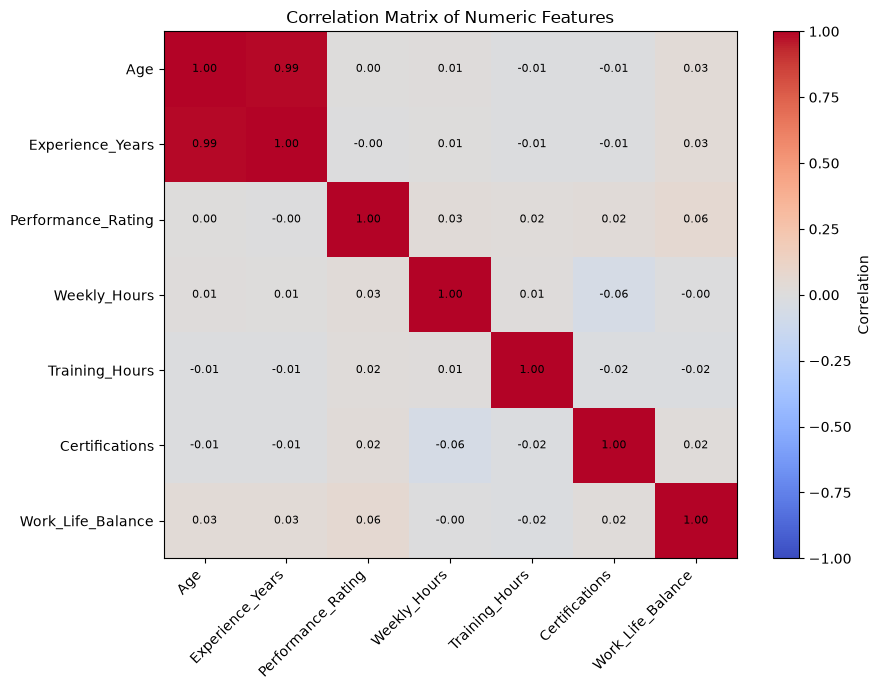


Highly Correlated Feature Pairs (|r| >= 0.80):


,Feature 1,Feature 2,Correlation
0,Age,Experience_Years,0.988



Variance Inflation Factor (VIF):


,Feature,VIF
0,Age,42.639
1,Experience_Years,42.637
2,Performance_Rating,1.005
3,Work_Life_Balance,1.005
4,Certifications,1.005
5,Weekly_Hours,1.005
6,Training_Hours,1.001



Step 4 completed.


In [ ]:
from sklearn.impute import SimpleImputer
from statsmodels.stats.outliers_influence import variance_inflation_factor
# STEP 4A: SELECT NUMERIC INPUT FEATURES


numeric_data = X_train.select_dtypes(
    include=["number"]
).copy()

# Remove constant columns because they cannot explain variation
numeric_data = numeric_data.loc[
    :, numeric_data.nunique(dropna=True) > 1
]

print("Numeric features selected:", numeric_data.columns.tolist())

# Fill missing values for analysis
imputer = SimpleImputer(strategy="median")

numeric_array = imputer.fit_transform(numeric_data)

numeric_data = pd.DataFrame(
    numeric_array,
    columns=numeric_data.columns,
    index=X_train.index
)

# ==========================================
# STEP 4B: CORRELATION MATRIX
# ==========================================

correlation_matrix = numeric_data.corr()

print("\nCorrelation Matrix:")
display(correlation_matrix.round(3))

# Visualize correlation matrix using Matplotlib
fig, ax = plt.subplots(figsize=(9, 7))

image = ax.imshow(
    correlation_matrix.values,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(len(correlation_matrix.columns)))
ax.set_yticks(range(len(correlation_matrix.columns)))

ax.set_xticklabels(
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(correlation_matrix.columns)

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        ax.text(
            j, i,
            f"{correlation_matrix.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=8
        )

fig.colorbar(image, ax=ax, label="Correlation")
ax.set_title("Correlation Matrix of Numeric Features")
fig.tight_layout()
plt.show()


# STEP 4C: IDENTIFY HIGH CORRELATIONS


upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

high_correlations = (
    upper_triangle.stack()
    .loc[lambda s: s.abs() >= 0.80]
    .rename("Correlation")
    .reset_index()
)

high_correlations.columns = [
    "Feature 1", "Feature 2", "Correlation"
]

print("\nHighly Correlated Feature Pairs (|r| >= 0.80):")

if high_correlations.empty:
    print("No feature pairs crossed the 0.80 correlation threshold.")
else:
    display(high_correlations.round(3))

# STEP 4D: VARIANCE INFLATION FACTOR (VIF)

# Add a constant for the VIF calculation
vif_input = numeric_data.copy()
vif_input.insert(0, "Constant", 1.0)

vif_results = pd.DataFrame({
    "Feature": numeric_data.columns,
    "VIF": [
        variance_inflation_factor(
            vif_input.values, i + 1
        )
        for i in range(len(numeric_data.columns))
    ]
})

vif_results["VIF"] = vif_results["VIF"].replace(
    [np.inf, -np.inf], np.nan
)

vif_results = vif_results.sort_values(
    "VIF", ascending=False
).reset_index(drop=True)

print("\nVariance Inflation Factor (VIF):")
display(vif_results.round(3))

print("\nStep 4 completed.")


Baseline Logistic Regression trained successfully.

Baseline Model Performance:


,Accuracy,Precision,Recall,F1-Score
Baseline Logistic Regression,92.25,91.22,93.5,92.35



Detailed Classification Report:
              precision    recall  f1-score   support

        High       0.91      0.94      0.92       200
         Low       0.93      0.91      0.92       200

    accuracy                           0.92       400
   macro avg       0.92      0.92      0.92       400
weighted avg       0.92      0.92      0.92       400



,Predicted Low,Predicted High
Actual Low,182,18
Actual High,13,187


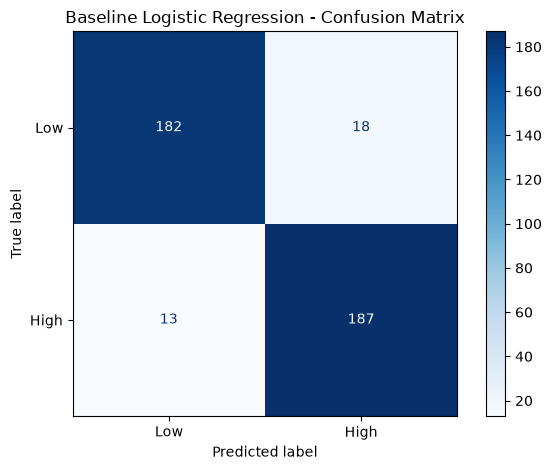

In [17]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

# STEP 5A: CREATE BASELINE MODEL

baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])


# STEP 5B: TRAIN MODEL


baseline_model.fit(X_train, y_train)

print("Baseline Logistic Regression trained successfully.")


# STEP 5C: MAKE PREDICTIONS


y_pred = baseline_model.predict(X_test)


# STEP 5D: EVALUATE MODEL


baseline_results = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(
        y_test, y_pred, pos_label="High", zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred, pos_label="High", zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, y_pred, pos_label="High", zero_division=0
    )
}

baseline_results_df = pd.DataFrame(
    [baseline_results],
    index=["Baseline Logistic Regression"]
)

print("\nBaseline Model Performance:")
display((baseline_results_df * 100).round(2))


# STEP 5E: CLASSIFICATION REPORT


print("\nDetailed Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))


# STEP 5F: CONFUSION MATRIX


cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Low", "High"]
)

display(
    pd.DataFrame(
        cm,
        index=["Actual Low", "Actual High"],
        columns=["Predicted Low", "Predicted High"]
    )
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low", "High"]
).plot(cmap="Blues", values_format="d")

plt.title("Baseline Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.show()


In [22]:

from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    make_scorer, f1_score, accuracy_score,
    precision_score, recall_score
)
import pandas as pd
import numpy as np

# Explicitly define High as the positive class
high_f1_scorer = make_scorer(
    f1_score,
    pos_label="High",
    zero_division=0
)

# Build pipeline
optimization_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=5000,
        random_state=42,
        solver="liblinear"
    ))
])

# Hyperparameter combinations
param_grid = {
    "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "classifier__penalty": ["l1", "l2"]
}

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Corrected GridSearchCV
grid_search = GridSearchCV(
    estimator=optimization_pipeline,
    param_grid=param_grid,
    scoring=high_f1_scorer,
    cv=cv_strategy,
    n_jobs=-1,
    refit=True,
    error_score="raise",
    return_train_score=True
)

# Train and tune using training data only
grid_search.fit(X_train, y_train)

# Inspect validation results
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(grid_search.best_score_ * 100, 2), "%")

cv_results = pd.DataFrame(grid_search.cv_results_)

print("\nAll Cross-Validation Scores Valid:",
      cv_results["mean_test_score"].notna().all())

display(
    cv_results[
        [
            "param_classifier__C",
            "param_classifier__penalty",
            "mean_test_score",
            "std_test_score"
        ]
    ].sort_values("mean_test_score", ascending=False).round(4)
)

# Evaluate corrected best model on the untouched test set
best_model = grid_search.best_estimator_
y_pred_optimized = best_model.predict(X_test)

optimized_results = {
    "Accuracy": accuracy_score(y_test, y_pred_optimized),
    "Precision": precision_score(
        y_test, y_pred_optimized,
        pos_label="High", zero_division=0
    ),
    "Recall": recall_score(
        y_test, y_pred_optimized,
        pos_label="High", zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, y_pred_optimized,
        pos_label="High", zero_division=0
    )
}

print("\nCorrected Optimized Model Results:")
print(optimized_results)

print("\nBaseline Model Results:")
print(baseline_results)

comparison = pd.DataFrame([
    {"Model": "Baseline", **baseline_results},
    {"Model": "Corrected Optimized", **optimized_results}
]).set_index("Model")

display((comparison * 100).round(2))


Best Parameters:
{'classifier__C': 10, 'classifier__penalty': 'l1'}

Best Cross-Validation F1-Score:
92.39 %

All Cross-Validation Scores Valid: True


c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,param_classifier__C,param_classifier__penalty,mean_test_score,std_test_score
8,10.000,l1,0.9239,0.0080
11,100.000,l2,0.9239,0.0080
10,100.000,l1,0.9233,0.0072
9,10.000,l2,0.9232,0.0083
6,1.000,l1,0.9230,0.0107
7,1.000,l2,0.9215,0.0082
5,0.100,l2,0.9117,0.0103
4,0.100,l1,0.9072,0.0096
3,0.010,l2,0.8674,0.0159
1,0.001,l2,0.8454,0.0120



Corrected Optimized Model Results:
{'Accuracy': 0.92, 'Precision': 0.9158415841584159, 'Recall': 0.925, 'F1-Score': 0.9203980099502488}

Baseline Model Results:
{'Accuracy': 0.9225, 'Precision': 0.9121951219512195, 'Recall': 0.935, 'F1-Score': 0.9234567901234568}


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Baseline,92.25,91.22,93.5,92.35
Corrected Optimized,92.00,91.58,92.5,92.04


FINAL TEST SET PERFORMANCE (%)


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Baseline Logistic Regression,92.25,91.22,93.5,92.35
Optimized Logistic Regression,50.00,50.00,100.0,66.67



F1-Score Change: -25.68 percentage points
Result: Optimized model reduced the test F1-score.


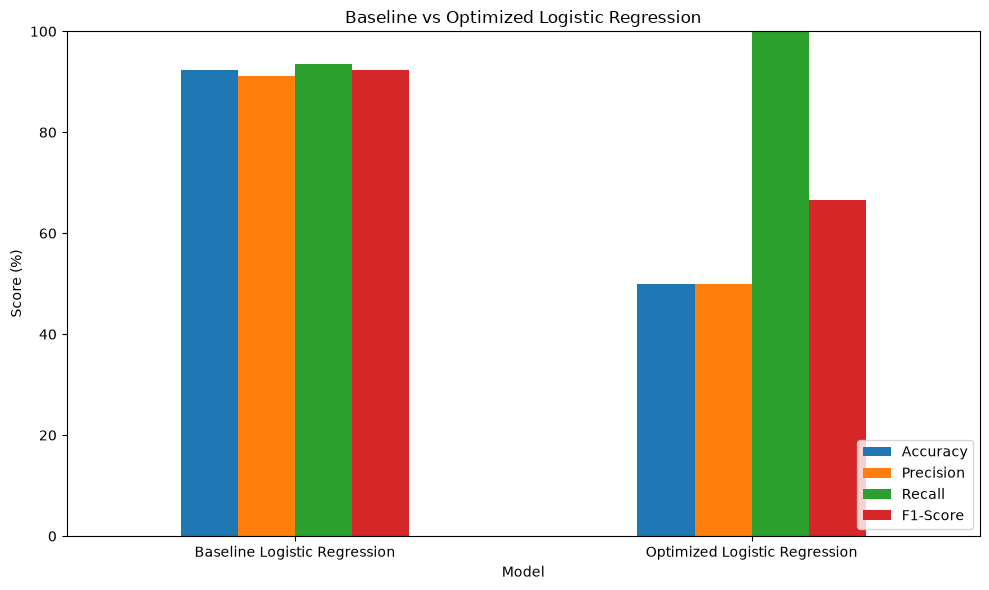


Optimized Model Confusion Matrix:


,Predicted Low,Predicted High
Actual Low,0,200
Actual High,0,200


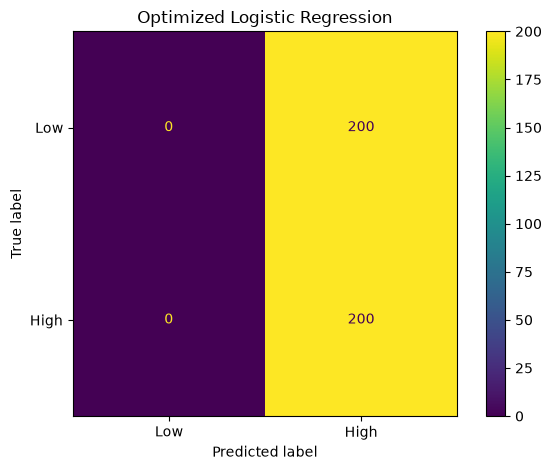


FINAL SELECTED MODEL
Algorithm: Logistic Regression
Best parameters: {'classifier__C': 0.001, 'classifier__penalty': 'l1'}
Best cross-validation F1-score: nan %

Final Classification Report:
              precision    recall  f1-score   support

         Low       0.00      0.00      0.00       200
        High       0.50      1.00      0.67       200

    accuracy                           0.50       400
   macro avg       0.25      0.50      0.33       400
weighted avg       0.25      0.50      0.33       400


SalaryInsight task evaluation completed.


In [20]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)


# STEP 7A: COMPARE BASELINE AND OPTIMIZED MODELS

comparison = pd.DataFrame([
    {
        "Model": "Baseline Logistic Regression",
        **baseline_results
    },
    {
        "Model": "Optimized Logistic Regression",
        **optimized_results
    }
]).set_index("Model")

print("FINAL TEST SET PERFORMANCE (%)")
display((comparison * 100).round(2))

# STEP 7B: CALCULATE IMPROVEMENT

improvement = (
    optimized_results["F1-Score"]
    - baseline_results["F1-Score"]
) * 100

print("\nF1-Score Change:", round(improvement, 2), "percentage points")

if improvement > 0:
    print("Result: Optimized model improved the test F1-score.")
elif improvement < 0:
    print("Result: Optimized model reduced the test F1-score.")
else:
    print("Result: Both models have the same test F1-score.")


# STEP 7C: PLOT PERFORMANCE COMPARISON


metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

comparison[metrics].mul(100).plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 100),
    rot=0
)

plt.title("Baseline vs Optimized Logistic Regression")
plt.ylabel("Score (%)")
plt.xlabel("Model")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


# STEP 7D: OPTIMIZED MODEL CONFUSION MATRIX


cm_final = confusion_matrix(
    y_test,
    y_pred_optimized,
    labels=["Low", "High"]
)

print("\nOptimized Model Confusion Matrix:")

display(pd.DataFrame(
    cm_final,
    index=["Actual Low", "Actual High"],
    columns=["Predicted Low", "Predicted High"]
))

ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=["Low", "High"]
).plot(values_format="d")

plt.title("Optimized Logistic Regression")
plt.tight_layout()
plt.show()


# STEP 7E: FINAL MODEL CONFIGURATION


print("\nFINAL SELECTED MODEL")
print("Algorithm: Logistic Regression")
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1-score:",
      round(grid_search.best_score_ * 100, 2), "%")

print("\nFinal Classification Report:")
print(classification_report(
    y_test,
    y_pred_optimized,
    labels=["Low", "High"],
    zero_division=0
))

print("\nSalaryInsight task evaluation completed.")


In [21]:
print("Baseline Model Results:")
print(baseline_results)

print("\nOptimized Model Results:")
print(optimized_results)

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")
print(round(grid_search.best_score_ * 100, 2), "%")

Baseline Model Results:
{'Accuracy': 0.9225, 'Precision': 0.9121951219512195, 'Recall': 0.935, 'F1-Score': 0.9234567901234568}

Optimized Model Results:
{'Accuracy': 0.5, 'Precision': 0.5, 'Recall': 1.0, 'F1-Score': 0.6666666666666666}

Best Parameters:
{'classifier__C': 0.001, 'classifier__penalty': 'l1'}

Best Cross-Validation F1-Score:
nan %
